In [2]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from skimage.metrics import mean_squared_error

In [3]:
data = pd.read_csv('data.csv')

In [4]:
data.head()

,Car,Model,Volume,Weight,CO2
0,Toyoty,Aygo,1000,790,99
1,Mitsubishi,Space Star,1200,1160,95
2,Skoda,Citigo,1000,929,95
3,Fiat,500,900,865,90
4,Mini,Cooper,1500,1140,105


In [5]:
new_data = data.drop(columns=['Car' ,'Model'])
new_data.head()

,Volume,Weight,CO2
0,1000,790,99
1,1200,1160,95
2,1000,929,95
3,900,865,90
4,1500,1140,105


In [6]:
X = new_data[['Volume' ,'Weight']]
y = new_data['CO2']

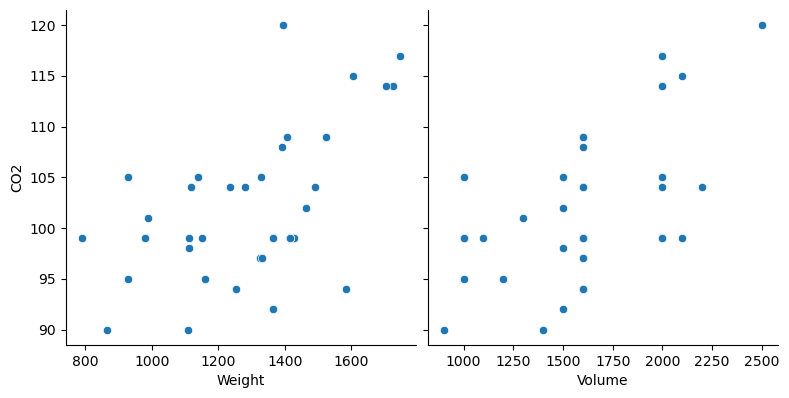

In [7]:
sns.pairplot(new_data, x_vars=['Weight', 'Volume'], y_vars='CO2', height=4, aspect=1, kind='scatter')
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
reg_model = linear_model.LinearRegression()
reg_model = LinearRegression().fit(X_train, y_train)

In [10]:
y_pred = reg_model.predict(X_test)

In [17]:
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error(MSE):{mse:.2f}')


Mean Squared Error(MSE):58.08


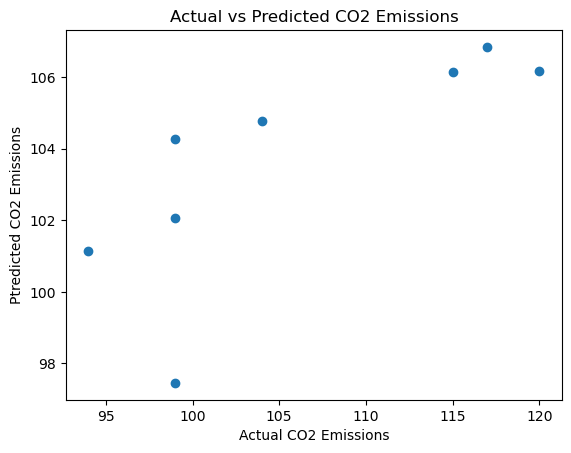

In [12]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual CO2 Emissions')
plt.ylabel('Ptredicted CO2 Emissions')
plt.title('Actual vs Predicted CO2 Emissions')
plt.show()

In [13]:
reg_model_diff = pd.DataFrame({'Actual value': y_test, 'Predicted value': y_pred})
reg_model_diff

,Actual value,Predicted value
35,120,106.162301
13,94,101.152581
26,104,104.783275
30,115,106.137684
16,99,102.062149
31,117,106.843891
21,99,104.284220
12,99,97.453233


Text(0.5, 0, 'CO2')

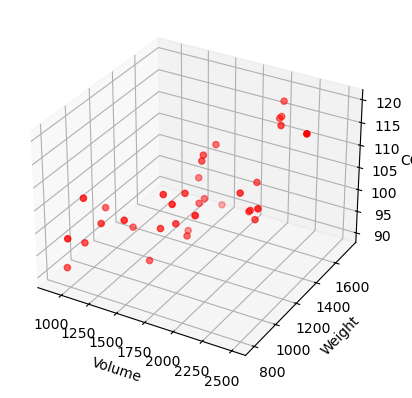

In [14]:
# Import library to produce a 3D plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

x1 = X["Volume"]
x2 = X["Weight"]

ax.scatter(x1, x2, y, c='r', marker='o')

# Set axis labels
ax.set_xlabel('Volume')
ax.set_ylabel('Weight')
ax.set_zlabel('CO2')

In [20]:
intercept = reg_model.intercept_ #intercept
slope = reg_model.coef_ [0]#slope
print(f"Intercept: {intercept}")
print(f"Slope:{slope}")

Intercept: 84.21502006695282
Slope:0.004287414249075688


In [15]:
new_data1 = pd.DataFrame({'Volume': [650], 'Weight': [770]})
predicted_CO2 = reg_model.predict(new_data1)
print(f'Predicted CO2 emissions:{predicted_CO2[0]:.2f}')

Predicted CO2 emissions:93.20
